# NBA Archetypes: Exploratory Data Analysis (EDA)


In [1]:
# packages
import csv
from collections import Counter
from pathlib import Path
import matplotlib.pyplot as plt

from IPython.display import HTML, display
import html

In [2]:
# Load Data from preprocessed csvs from fetch_nba.py 
# create a tables dictionary w/ columns and rows to perform analysis later
data_dir = Path('data')
tables = {}
for path in sorted(data_dir.glob('*.csv')):
    with path.open(newline='', encoding='utf-8-sig') as f:
        reader = csv.DictReader(f)
        columns = reader.fieldnames or []
        rows = list(reader)
    tables[path.stem] = {'columns': columns, 'rows': rows}
print(f'Loaded {len(tables)} CSV files from {data_dir.resolve()}')


Loaded 10 CSV files from /Users/dannykuei/Documents/STA 221/Project/NBA-Archetypes-Roster-Builder/data


## Dataset sizes and season coverage

Season tables cover five seasons from 2021–22 through 2025–26. 
All datasets contain player-season pairs while `game_logs.csv` cover a stats of a player per game. 

In [3]:
# table header
print(f'{"File":<20} {"Rows":>9} {"Cols":>5} {"Missing Values":>16} {"Duplicates":>12}  Seasons')

# iterate over each table to find how many total observations and variables as well as observations per season
for name, table in tables.items():
    rows, cols = table['rows'], table['columns']
    seasons = Counter((r.get('SEASON') or r.get('SEASON_YEAR') or '').strip() for r in rows)
    seasons.pop('', None)
    missing_rows = sum(any(not (r.get(c) or '').strip() for c in cols) for r in rows)
    duplicates = len(rows) - len({tuple(r.get(c, '') for c in cols) for r in rows})
    season_text = ', '.join(f'{s}: {n}' for s,n in sorted(seasons.items())) or '—'
    print(f'{name:<20} {len(rows):>9,} {len(cols):>5} {missing_rows:>16,} {duplicates:>12,}  {season_text}')


File                      Rows  Cols   Missing Values   Duplicates  Seasons
defend_rim               2,808    15                0            0  2021-22: 581, 2022-23: 530, 2023-24: 562, 2024-25: 559, 2025-26: 576
game_logs              131,291    73                0            0  2021-22: 26039, 2022-23: 25894, 2023-24: 26401, 2024-25: 26306, 2025-26: 26651
hustle                   2,846    29                0            0  2021-22: 596, 2022-23: 535, 2023-24: 567, 2024-25: 567, 2025-26: 581
player_advanced          2,867    80                0            0  2021-22: 605, 2022-23: 539, 2023-24: 572, 2024-25: 569, 2025-26: 582
player_index               724    28              432            0  2021-22: 172, 2022-23: 99, 2023-24: 140, 2024-25: 130, 2025-26: 183
player_scoring           2,867    54                0            0  2021-22: 605, 2022-23: 539, 2023-24: 572, 2024-25: 569, 2025-26: 582
player_stats             2,867    24               36            0  2021-22: 605, 2022-23: 53

The data tracks with what we expect as the number of players on NBA roster is 18. With 30 teams, we expect at least 540 players a season with potentially more due to players getting waived/signed. The 540 players a season estimate totals to over 2700 player-season pairs across the course for 5 seasons. 

## Missingness

we will analyze `player_index.csv`, `player_stats.csv`, and `shot_zones.csv` to see if the missing values are essential to our analyze. If so we need to consider whether to drop values or use imputation methods. 

In [4]:
# Check missingness in the three datasets identified.
missingness_tables = ['player_index', 'player_stats', 'shot_zones']
missing = []

for name in missingness_tables:
    table = tables[name]
    rows, cols = table['rows'], table['columns']
    counts = [
        (col, sum(not (row.get(col) or '').strip() for row in rows))
        for col in cols
    ]
    counts = [(col, count) for col, count in counts if count]

    print(f'\n{name}.csv')
    if counts:
        for col, count in sorted(counts, key=lambda item: item[1], reverse=True):
            print(f'  {col}: {count:,} ({count / len(rows):.1%})')
            missing.append((f'{name}: {col}', count))
    else:
        print('  no blank cells')



player_index.csv
  DRAFT_YEAR: 324 (44.8%)
  DRAFT_ROUND: 324 (44.8%)
  DRAFT_NUMBER: 324 (44.8%)
  JERSEY_NUMBER: 248 (34.3%)
  TEAM_SLUG: 236 (32.6%)
  TEAM_CITY: 236 (32.6%)
  TEAM_NAME: 236 (32.6%)
  TEAM_ABBREVIATION: 236 (32.6%)
  ROSTER_STATUS: 236 (32.6%)
  PTS: 11 (1.5%)
  REB: 11 (1.5%)
  AST: 11 (1.5%)
  COLLEGE: 2 (0.3%)
  WEIGHT: 1 (0.1%)

player_stats.csv
  DRAFT_NUMBER: 28 (1.0%)
  DRAFT_ROUND: 27 (0.9%)
  PLAYER_WEIGHT: 8 (0.3%)

shot_zones.csv
  Backcourt_FGM: 67 (2.3%)
  Backcourt_FGA: 67 (2.3%)
  Backcourt_FG_PCT: 67 (2.3%)
  Left Corner 3_FGM: 39 (1.4%)
  Left Corner 3_FGA: 39 (1.4%)
  Left Corner 3_FG_PCT: 39 (1.4%)
  Right Corner 3_FGM: 36 (1.3%)
  Right Corner 3_FGA: 36 (1.3%)
  Right Corner 3_FG_PCT: 36 (1.3%)
  Corner 3_FGM: 21 (0.7%)
  Corner 3_FGA: 21 (0.7%)
  Corner 3_FG_PCT: 21 (0.7%)
  Mid-Range_FGM: 10 (0.3%)
  Mid-Range_FGA: 10 (0.3%)
  Mid-Range_FG_PCT: 10 (0.3%)
  Restricted Area_FGM: 4 (0.1%)
  Restricted Area_FGA: 4 (0.1%)
  Restricted Area_FG_PCT: 

There are no major stats with missing values. Draft round and number missing can be explained by players being undrafted. Many shot zone stats have missing values which makes sense as some players dont shoot from certain spots. To handle this, we fill the shot zones as zero, but it is likely players who have missing shot zone values fail to meet the minutes criteria. 

## Summary Statistics

In [5]:
# Selected features
stat_col = {
    'AGE', 'GP', 'MIN', 'PTS', 'REB', 'AST', 'TOV', 'STL', 'BLK',
    'FG_PCT', 'FG3_PCT', 'FT_PCT', 'TS_PCT', 'USG_PCT', 'AST_PCT',
    'EFG_PCT', 'NET_RATING', 'PIE', 'FGA', 'FG3A', 'FGA_PG', 'FGM_PG',
}
defend_rim_col = {
    'FREQ', 'FGM_LT_06', 'FGA_LT_06', 'LT_06_PCT', 'NS_LT_06_PCT', 'PLUSMINUS',
}
hustle_col = {
    'CONTESTED_SHOTS', 'CONTESTED_SHOTS_2PT', 'CONTESTED_SHOTS_3PT', 'DEFLECTIONS',
    'CHARGES_DRAWN', 'SCREEN_ASSISTS', 'SCREEN_AST_PTS', 'OFF_LOOSE_BALLS_RECOVERED',
    'DEF_LOOSE_BALLS_RECOVERED', 'LOOSE_BALLS_RECOVERED', 'OFF_BOXOUTS', 'DEF_BOXOUTS',
    'BOX_OUTS', 'BOX_OUT_PLAYER_REBS', 'BOX_OUT_PLAYER_TEAM_REBS',
}

def summarize(values):
    numbers = sorted(float(v) for v in values if v is not None and str(v).strip())
    if not numbers:
        return None
    def quantile(p):
        pos = (len(numbers) - 1) * p
        lo = int(pos)
        hi = min(lo + 1, len(numbers) - 1)
        return numbers[lo] + (numbers[hi] - numbers[lo]) * (pos - lo)
    return [numbers[0], quantile(.25), quantile(.5), sum(numbers) / len(numbers), quantile(.75), numbers[-1]]

def fmt(value):
    return f'{value:,.3f}'.rstrip('0').rstrip('.')

for table_name in ['player_totals', 'player_advanced', 'player_scoring', 'shot_zones', 'hustle', 'defend_rim']:
    rows = tables[table_name]['rows']
    summaries = []
    for column in tables[table_name]['columns']:
        selected = (column in stat_col or column in hustle_col or column in defend_rim_col or column.startswith('PCT_') or column.endswith('_FG_PCT')) and not column.endswith('_RANK')
        if not selected:
            continue
        try:
            stats = summarize([row.get(column) for row in rows])
        except ValueError:
            stats = None
        if stats:
            summaries.append((column, stats))
    table_html = ['<h3>' + html.escape(table_name + '.csv') + '</h3>', '<table><thead><tr><th>Variable</th><th>Min</th><th>Q1</th><th>Median</th><th>Mean</th><th>Q3</th><th>Max</th></tr></thead><tbody>']
    for column, stats in summaries:
        table_html.append('<tr><th>' + html.escape(column) + '</th>' + ''.join('<td>' + fmt(value) + '</td>' for value in stats) + '</tr>')
    table_html.append('</tbody></table>')
    display(HTML(''.join(table_html)))


Variable,Min,Q1,Median,Mean,Q3,Max
AGE,19,23,25,26.206,29,43
GP,1,23,51,45.794,68,84
MIN,0.667,264.643,914.383,"1,035.741","1,730.216","3,036.093"
FGA,0,77,275,380.652,579,"1,656"
FG_PCT,0,0.406,0.451,0.45,0.5,1
FG3A,0,16,97,153.637,247,876
FG3_PCT,0,0.263,0.336,0.301,0.38,1
FT_PCT,0,0.667,0.763,0.71,0.834,1
REB,0,44,147,188.19,278,"1,120"
AST,0,18,68,111.483,154,880


Variable,Min,Q1,Median,Mean,Q3,Max
AGE,19,23,25,26.206,29,43
GP,1,23,51,45.794,68,84
MIN,0.4,11.6,18.9,19.282,27.3,43.5
NET_RATING,-250,-7.3,-1.1,-2.45,3.7,133.3
AST_PCT,0,0.078,0.117,0.141,0.19,1
EFG_PCT,0,0.485,0.533,0.518,0.574,1.25
TS_PCT,0,0.517,0.565,0.547,0.604,1.25
USG_PCT,0,0.139,0.169,0.177,0.208,0.5
PIE,-0.286,0.067,0.086,0.087,0.109,0.519
FGA,0,77,275,380.652,579,"1,656"


Variable,Min,Q1,Median,Mean,Q3,Max
AGE,19,23,25,26.206,29,43
GP,1,23,51,45.794,68,84
MIN,0.4,11.6,18.9,19.282,27.3,43.5
PCT_FGA_2PT,0,0.439,0.574,0.586,0.722,1
PCT_FGA_3PT,0,0.274,0.422,0.408,0.555,1
PCT_PTS_2PT,0,0.368,0.495,0.5,0.63,1
PCT_PTS_2PT_MR,0,0.009,0.039,0.058,0.083,1
PCT_PTS_3PT,0,0.173,0.343,0.34,0.491,1
PCT_PTS_FB,0,0.074,0.12,0.126,0.166,1
PCT_PTS_FT,0,0.092,0.14,0.16,0.184,1


Variable,Min,Q1,Median,Mean,Q3,Max
AGE,19,23,25,26.206,29,43
Restricted Area_FG_PCT,0,0.579,0.647,0.62,0.708,1
In The Paint (Non-RA)_FG_PCT,0,0.321,0.411,0.384,0.48,1
Mid-Range_FG_PCT,0,0.2,0.369,0.336,0.457,1
Left Corner 3_FG_PCT,0,0.125,0.333,0.306,0.44,1
Right Corner 3_FG_PCT,0,0.029,0.333,0.304,0.441,1
Above the Break 3_FG_PCT,0,0.238,0.328,0.288,0.374,1
Backcourt_FG_PCT,0,0,0,0.011,0,1
Corner 3_FG_PCT,0,0.227,0.351,0.315,0.429,1


Variable,Min,Q1,Median,Mean,Q3,Max
AGE,19,23,25,26.217,29,43
MIN,0,260.25,913.5,"1,032.739","1,731.75","3,004"
CONTESTED_SHOTS,0,46,151,188.887,282,"1,360"
CONTESTED_SHOTS_2PT,0,24,81,114.301,157.75,"1,225"
CONTESTED_SHOTS_3PT,0,19,64,74.585,118,314
DEFLECTIONS,0,16,54.5,65.713,102,448
CHARGES_DRAWN,0,0,0,1.752,2,43
SCREEN_ASSISTS,0,4,15,35.885,37,488
SCREEN_AST_PTS,0,9,35,83.315,86,"1,157"
OFF_LOOSE_BALLS_RECOVERED,0,2,9,10.547,16,47


Variable,Min,Q1,Median,Mean,Q3,Max
AGE,19,23,25,26.233,29,43
GP,1,22,50,44.952,67,84
FREQ,0.067,0.311,0.361,0.363,0.412,1
FGM_LT_06,0,26,81,93.103,143,426
FGA_LT_06,1,41,126,150.025,228,690
LT_06_PCT,0,0.583,0.632,0.632,0.681,1
NS_LT_06_PCT,0,0.621,0.63,0.627,0.637,0.833
PLUSMINUS,-0.769,-0.048,0.003,0.006,0.056,0.586


## Player-season Keys 

A season table should have one row per player-season. We check if there are duplicate player-season pairs. 

In [6]:
id_cols = ['PLAYER_ID', 'PERSON_ID', 'CLOSE_DEF_PERSON_ID']
keys, team_keys = {}, {}
for name, table in tables.items():
    cols, rows = table['columns'], table['rows']
    ident = next((c for c in id_cols if c in cols), None)
    if ident and 'SEASON' in cols:
        keys[name] = {(r[ident].strip(), r['SEASON'].strip()) for r in rows if r.get(ident) and r.get('SEASON')}
        teamcol = 'TEAM_ID' if 'TEAM_ID' in cols else ('PLAYER_LAST_TEAM_ID' if 'PLAYER_LAST_TEAM_ID' in cols else None)
        if teamcol:
            team_keys[name] = {(r[ident].strip(), r[teamcol].strip(), r['SEASON'].strip()) for r in rows if r.get(ident) and r.get('SEASON')}
base = keys['player_totals']
print(f'{"File":<20} {"Rows":>9} {"Player seasons":>16} {"Team-season keys":>18} {"Repeated player-season rows":>28}')
for name, tablekeys in keys.items():
    nrows = len(tables[name]['rows'])
    overlap = len(base & tablekeys)
    print(f'{name:<20} {nrows:>9,} {len(tablekeys):>16,} {len(team_keys.get(name,set())):>18,} {nrows-len(tablekeys):>28,}')




File                      Rows   Player seasons   Team-season keys  Repeated player-season rows
defend_rim               2,808            2,807              2,807                            1
game_logs              131,291            2,867              3,296                      128,424
hustle                   2,846            2,846              2,846                            0
player_advanced          2,867            2,867              2,867                            0
player_index               724              724                724                            0
player_scoring           2,867            2,867              2,867                            0
player_stats             2,867            2,867              2,867                            0
player_totals            2,867            2,867              2,867                            0
shot_zones               2,867            2,867              2,867                            0


Naturally, `game_logs.csv` will have many games (duplicates) for each player-season key, so we ignore that. We identify 1 duplicate in `defend_rim.csv`. 

In [7]:
# identify duplicate
seen = Counter((r['CLOSE_DEF_PERSON_ID'].strip(),r['SEASON'].strip()) for r in tables['defend_rim']['rows'])
for (pid,season),n in seen.items():
    if n>1:
        row=next(r for r in tables['defend_rim']['rows'] if r['CLOSE_DEF_PERSON_ID'].strip()==pid and r['SEASON'].strip()==season)
        print(f'Repeated key: {row["PLAYER_NAME"]}, {season} ({n} rows)')

Repeated key: Mikal Bridges, 2022-23 (2 rows)


In [8]:
# Display Mikal Bridges' two defend_rim rows for 2022-23.
mikal_rows = [
    row for row in tables['defend_rim']['rows']
    if row['PLAYER_NAME'].strip() == 'Mikal Bridges' and row['SEASON'].strip() == '2022-23'
]
columns = [
    'PLAYER_LAST_TEAM_ABBREVIATION', 'PLAYER_POSITION', 'AGE', 'GP', 'G', 'FREQ',
    'FGM_LT_06', 'FGA_LT_06', 'LT_06_PCT', 'NS_LT_06_PCT', 'PLUSMINUS',
]
for row in mikal_rows:
    print({column: row[column] for column in columns})

{'PLAYER_LAST_TEAM_ABBREVIATION': 'BKN', 'PLAYER_POSITION': 'F', 'AGE': '26.0', 'GP': '56', 'G': '55', 'FREQ': '0.378', 'FGM_LT_06': '170', 'FGA_LT_06': '276', 'LT_06_PCT': '0.616', 'NS_LT_06_PCT': '0.629', 'PLUSMINUS': '-0.013'}
{'PLAYER_LAST_TEAM_ABBREVIATION': 'BKN', 'PLAYER_POSITION': 'G-F', 'AGE': '26.0', 'GP': '26', 'G': '26', 'FREQ': '0.429', 'FGM_LT_06': '93', 'FGA_LT_06': '164', 'LT_06_PCT': '0.567', 'NS_LT_06_PCT': '0.633', 'PLUSMINUS': '-0.066'}


Mikal Bridges was traded midseason from the Phoenix Suns to the Brooklyn Nets, and it seems like this data did not combine the data. It's possible, it's because his listed positions are different (F vs G-F). We fix this in `feature_engineering.py` in which we will combine the data together. The exact process will be to sum `FGM_LT_06` and `FGA_LT_06` to recalculate `LT_06_PCT` (summed makes divided by summed attempts). Then we can use this to recalculate `NS_LT_06_PCT` and `PLUSMINUS`.

## Per-game production

We first plot histograms for basic stats of points, rebounds, assists, and 3pt attempts per game. For later analysis, we will use per 36 minute metrics. 

In [9]:
totals = tables['player_totals']['rows']
regular = []
for r in totals:
    gp=float(r['GP'] or 0)
    if gp>=20:
        regular.append((float(r['PTS'] or 0)/gp,float(r['REB'] or 0)/gp,float(r['AST'] or 0)/gp,float(r['FG3A'] or 0)/gp))
print(f'Player-seasons with GP >= 20: {len(regular):,} of {len(totals):,}')
fig, axes = plt.subplots(2,2,figsize=(10,7))
for ax,i,title in zip(axes.flat,range(4),['Points per game','Rebounds per game','Assists per game','Three-point attempts per game']):
    ax.hist([row[i] for row in regular],bins=25,color='#258c72',edgecolor='white')
    ax.set_title(title)
    ax.set_ylabel('Player-seasons')
fig.tight_layout()
plt.show()


Player-seasons with GP >= 20: 2,232 of 2,867


<Figure size 1000x700 with 4 Axes>

The plots all seem to produce a right skew which makes sense as there will be few players who will obtain much higher stats and vs many players who have not much production.  

## Per-36 production (400-minute minimum)

For each player-season with at least 400 minutes, calculate points, rebounds, assists, blocks, and steals per 36 minutes. This keeps the analysis at one row per player-season and makes rates comparable across playing time.

In [10]:
min_minutes = 400
per36_stats = ['PTS', 'REB', 'AST', 'BLK', 'STL']
totals = tables['player_totals']['rows']
per36_rows = []
season_counts, season_totals = Counter(), Counter()

for row in totals:
    season = row['SEASON']
    season_totals[season] += 1
    minutes = float(row['MIN'] or 0)
    if minutes < min_minutes:
        continue
    season_counts[season] += 1
    item = {key: row.get(key, '') for key in ['PLAYER_ID', 'PLAYER_NAME', 'SEASON', 'GP', 'MIN']}
    for stat in per36_stats:
        item[f'{stat}_PER_36'] = float(row[stat] or 0) / minutes * 36
    per36_rows.append(item)

output_path = Path('data/processed/player_per36_400min.csv')
output_path.parent.mkdir(parents=True, exist_ok=True)
with output_path.open('w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=list(per36_rows[0]))
    writer.writeheader()
    writer.writerows(per36_rows)

print(f'Player-seasons with at least {min_minutes:,} minutes: {len(per36_rows):,}')
print(f'Saved per-36 data to {output_path}') # save 
print('{:<12} {:>9} {:>20} {:>9}'.format('Season', 'Eligible', 'All player-seasons', 'Share'))
for season in sorted(season_totals):
    eligible, total = season_counts[season], season_totals[season]
    print(f'{season:<12} {eligible:>9,} {total:>20,} {eligible / total:>8.1%}')

def quantile(values, p):
    values = sorted(values)
    position = (len(values) - 1) * p
    lower = int(position)
    upper = min(lower + 1, len(values) - 1)
    return values[lower] + (values[upper] - values[lower]) * (position - lower)

print('\nPer-36 summary statistics')
print('{:<14} {:>9} {:>9} {:>9} {:>9} {:>9} {:>9}'.format('Feature', 'Min', 'Q1', 'Median', 'Mean', 'Q3', 'Max'))
for stat in per36_stats:
    values = [row[f'{stat}_PER_36'] for row in per36_rows]
    summary = [min(values), quantile(values, .25), quantile(values, .5), sum(values) / len(values), quantile(values, .75), max(values)]
    print(f'{stat + "_PER_36":<14}' + ''.join(f'{value:>9.2f}' for value in summary))



Player-seasons with at least 400 minutes: 1,979
Saved per-36 data to data/processed/player_per36_400min.csv
Season        Eligible   All player-seasons     Share
2021-22            396                  605    65.5%
2022-23            388                  539    72.0%
2023-24            385                  572    67.3%
2024-25            401                  569    70.5%
2025-26            409                  582    70.3%

Per-36 summary statistics
Feature              Min        Q1    Median      Mean        Q3       Max
PTS_PER_36         3.85    12.56    15.24    16.09    18.96    37.20
REB_PER_36         1.75     4.42     5.76     6.61     8.26    18.86
AST_PER_36         0.53     2.11     3.10     3.67     4.76    12.18
BLK_PER_36         0.00     0.33     0.56     0.74     0.94     4.34
STL_PER_36         0.12     0.87     1.12     1.18     1.40     4.50


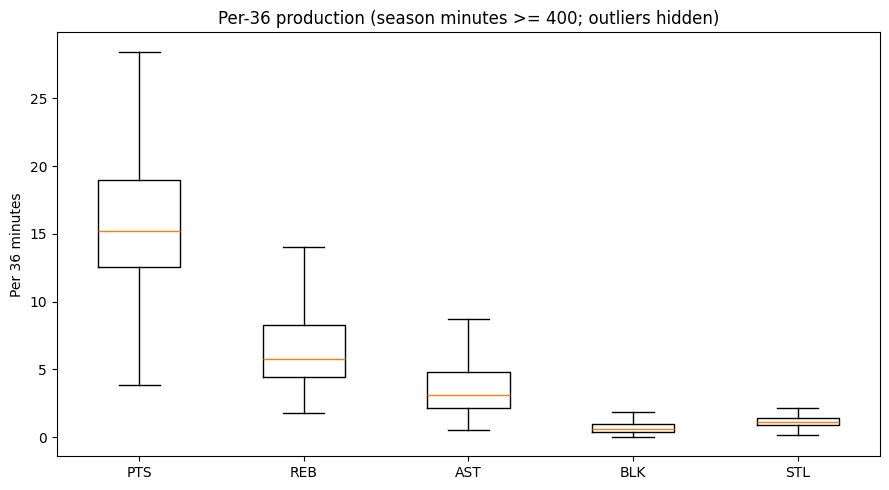

In [11]:
# plot
fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot(
    [[row[f'{stat}_PER_36'] for row in per36_rows] for stat in per36_stats],
    showfliers=False,
)
ax.set_xticks(range(1, len(per36_stats) + 1), labels=per36_stats)
ax.set_ylabel('Per 36 minutes')
ax.set_title('Per-36 production (season minutes >= 400; outliers hidden)')
fig.tight_layout()
plt.show()

## Shot Zone Heatmap
This chart will be a season by season heatmap to identify what types of shots are the most common in the NBA. For consistency, we will include the same data points as before (players who played 400 minutes in a season). We omit backcourt attempts. 

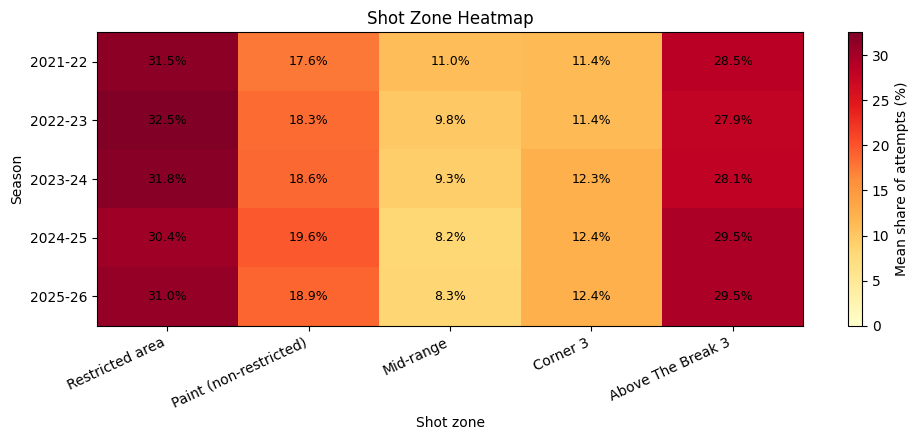

In [12]:
shot_zones = [
    ('Restricted Area_FGA', 'Restricted area'),
    ('In The Paint (Non-RA)_FGA', 'Paint (non-restricted)'),
    ('Mid-Range_FGA', 'Mid-range'),
    ('corner_3', 'Corner 3'),
    ('Above the Break 3_FGA', 'Above The Break 3'),
]

totals_by_key = {
    (row['PLAYER_ID'].strip(), row['SEASON'].strip()): row
    for row in tables['player_totals']['rows']
}
season_shares = {}
for row in tables['shot_zones']['rows']:
    key = (row['PLAYER_ID'].strip(), row['SEASON'].strip())
    total_row = totals_by_key.get(key)
    if total_row is None or float(total_row['MIN'] or 0) < min_minutes:
        continue
    attempts = {
        'Restricted Area_FGA': float(row.get('Restricted Area_FGA') or 0),
        'In The Paint (Non-RA)_FGA': float(row.get('In The Paint (Non-RA)_FGA') or 0),
        'Mid-Range_FGA': float(row.get('Mid-Range_FGA') or 0),
        'corner_3': float(row.get('Left Corner 3_FGA') or 0) + float(row.get('Right Corner 3_FGA') or 0),
        'Above the Break 3_FGA': float(row.get('Above the Break 3_FGA') or 0),
    }
    zone_attempts = sum(attempts.values())
    if zone_attempts == 0:
        continue
    season = row['SEASON'].strip()
    season_shares.setdefault(season, []).append(
        [attempts[column] / zone_attempts for column, _ in shot_zones]
    )

seasons = sorted(season_shares)
mean_shares = [
    [sum(values[i] for values in season_shares[season]) / len(season_shares[season]) * 100
     for i in range(len(shot_zones))]
    for season in seasons
]

# plot
fig, ax = plt.subplots(figsize=(10, 4.5))
heatmap = ax.imshow(mean_shares, cmap='YlOrRd', aspect='auto', vmin=0)
ax.set_xticks(range(len(shot_zones)), labels=[label for _, label in shot_zones], rotation=25, ha='right')
ax.set_yticks(range(len(seasons)), labels=seasons)
ax.set_xlabel('Shot zone')
ax.set_ylabel('Season')
ax.set_title(f'Shot Zone Heatmap')
for i, row in enumerate(mean_shares):
    for j, value in enumerate(row):
        ax.text(j, i, f'{value:.1f}%', ha='center', va='center', color='black', fontsize=9)
fig.colorbar(heatmap, ax=ax, label='Mean share of attempts (%)')
fig.tight_layout()
plt.show()